# Signal Amplitude PETHs

This notebook aligns raw Z-Scored ΔF/F signals to a behavioral event
and explores the data at multiple levels of granularity (Pooled, Genotype, Exact Region).

In [1]:
import pickle
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tqdm import tqdm

# Add project root to path
try:
    project_root = Path(__file__).resolve().parents[2]
except NameError:
    project_root = Path("../../").resolve()

if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from fpcode.photometry.session_signals import prepare_region_traces, legacy_nearest_window


In [2]:
# CONFIGURATION
# Set to a specific key (e.g., "juvenile_first_sniff_min") or "all" to plot everything.
EVENT_KEY = "all"
PRE_SEC = 20
POST_SEC = 40
FPS = 20

pkl_path = project_root / "monoamine_interactions" / "data" / "sessions_jonathan_juvenile_intruder_dirty.pkl"


In [3]:
# 1. Load Data
print(f"Loading {pkl_path}...")
with open(pkl_path, "rb") as f:
    sessions = pickle.load(f)

# Deduplicate sessions by photometry_csv_path
unique_sessions = []
seen_csvs = set()
for s in sessions:
    csv_path = s.metadata.get('photometry_csv_path')
    if csv_path and csv_path not in seen_csvs:
        seen_csvs.add(csv_path)
        unique_sessions.append(s)
sessions = unique_sessions
print(f"Post-deduplication: {len(sessions)} unique biological sessions.")

# Identify all available events
all_events = set()
for s in sessions:
    all_events.update(s.metadata.get('timing_meta', {}).keys())
all_events = sorted(list(all_events))

events_to_process = all_events if EVENT_KEY == "all" else [EVENT_KEY]
print(f"Processing events: {events_to_process}")


Loading /home/fsp585/Desktop/FiberphotometryCode/monoamine_interactions/data/sessions_jonathan_juvenile_intruder_dirty.pkl...
Post-deduplication: 10 unique biological sessions.
Processing events: ['home_cage_min', 'homecage_removed_min', 'inarena_min', 'juvenile_first_sniff_min', 'juvenile_removed_min']


In [4]:
# 2. Extract Aligned Signals
extracted_signals = []
# We'll store expected_lengths per event to handle different windowing if needed
metadata_per_event = {}

for event in events_to_process:
    print(f"Aligning to: {event}")
    expected_length = None
    time_vec = None

    for s in tqdm(sessions, desc=f"Extracting {event}"):
        tm = s.metadata.get("timing_meta", {})
        t_event_min = tm.get(event)
        if pd.isna(t_event_min):
            continue

        if '470' not in s.photometry: continue

        df_470 = s.photometry['470']
        df_415 = s.photometry['415']
        ts_array = df_470['SystemTimestamp'].values

        t_start_sys = ts_array[0]
        target_ts_event = t_start_sys + (t_event_min * 60)

        start_idx, end_idx = legacy_nearest_window(
            ts_array, target_ts_event - PRE_SEC, target_ts_event + POST_SEC
        )

        if end_idx <= start_idx: continue

        curr_len = end_idx - start_idx
        if expected_length is None:
            expected_length = curr_len
            time_vec = np.linspace(-PRE_SEC, POST_SEC, expected_length)
            metadata_per_event[event] = {'time_vec': time_vec, 'expected_length': expected_length}

        if curr_len != expected_length:
            end_idx = start_idx + expected_length
            if end_idx > len(ts_array): continue

        genotype = s.metadata.get('genotype', 'Unknown')
        sm = s.metadata.get("signal_meta", {})
        region_map = {k: v.get("region") for k, v in sm.items() if v.get("region")}
        prepared = prepare_region_traces(s, normalization="global_zscore", errors="skip")
        if prepared.failures:
            print(f"Signal preparation skipped regions: {prepared.failures}")

        for r in region_map.values():
            try:
                slice_dff = prepared.traces[r][start_idx:end_idx]

                # Infer sensor
                sensor = "Unknown"
                if "DA" in r: sensor = "DA"
                elif "5HT" in r: sensor = "5HT"
                elif "NE" in r: sensor = "NE"

                extracted_signals.append({
                    'event': event,
                    'genotype': genotype,
                    'region': r,
                    'sensor': sensor,
                    'signal': slice_dff
                })
            except Exception:
                pass

df_signals = pd.DataFrame(extracted_signals)
print(f"Extracted {len(df_signals)} signal traces total.")


Aligning to: home_cage_min


Extracting home_cage_min: 100%|██████████| 10/10 [00:01<00:00,  5.07it/s]


Aligning to: homecage_removed_min


Extracting homecage_removed_min: 100%|██████████| 10/10 [00:01<00:00,  5.10it/s]


Aligning to: inarena_min


...

Aligning to: juvenile_first_sniff_min


Extracting juvenile_first_sniff_min: 100%|██████████| 10/10 [00:01<00:00,  5.09it/s]


Aligning to: juvenile_removed_min


Extracting juvenile_removed_min: 100%|██████████| 10/10 [00:01<00:00,  5.17it/s]

Extracted 70 signal traces total.


In [5]:
# Helper plotting function
def plot_group(df, groupby_cols, title, filename, event_name):
    # Filter by event
    df_ev = df[df['event'] == event_name]
    if len(df_ev) == 0: return

    # Get correct time_vec for this event
    time_vec = metadata_per_event[event_name]['time_vec']

    groups = list(df_ev.groupby(groupby_cols))
    if len(groups) == 0: return

    n_groups = len(groups)
    fig, axes = plt.subplots(n_groups, 1, figsize=(10, 4 * n_groups), sharex=True, sharey=True)

    # Ensure axes is always an array even if n_groups=1
    if n_groups == 1:
        axes = [axes]

    for i, (name, group) in enumerate(groups):
        ax = axes[i]
        if isinstance(name, tuple):
            label = " | ".join(str(n) for n in name)
        else:
            label = str(name)

        arrays = np.vstack(group['signal'].values)
        mean_arr = np.nanmean(arrays, axis=0)
        std_err = np.nanstd(arrays, axis=0) / np.sqrt(len(arrays))

        line = ax.plot(time_vec, mean_arr, label=f"{label} (n={len(arrays)})", linewidth=2, color=f"C{i}")
        ax.fill_between(time_vec, mean_arr - std_err, mean_arr + std_err, alpha=0.2, color=line[0].get_color())

        ax.axvline(0, color='black', linestyle='--')
        ax.set_title(f"{label} (n={len(arrays)})")
        ax.set_ylabel("Z-Scored \u0394F/F")
        ax.grid(True, alpha=0.3)
    # Clean up event name for display (remove _min and replace underscores)
    display_name = event_name.replace('_min', '').replace('_', ' ').title()

    axes[-1].set_xlabel(f"Time relative to {display_name} (s)")
    plt.suptitle(f"{title} - {display_name}", y=1.02, fontsize=14)
    plt.tight_layout()

    # Save to outputs dir
    out_dir = project_root / "monoamine_interactions" / "outputs" / "04_signal_peths"
    out_dir.mkdir(parents=True, exist_ok=True)
    plt.savefig(out_dir / filename)
    plt.show()


## Run Analysis for all Events


--- GENERATING PLOTS FOR EVENT: home_cage_min ---


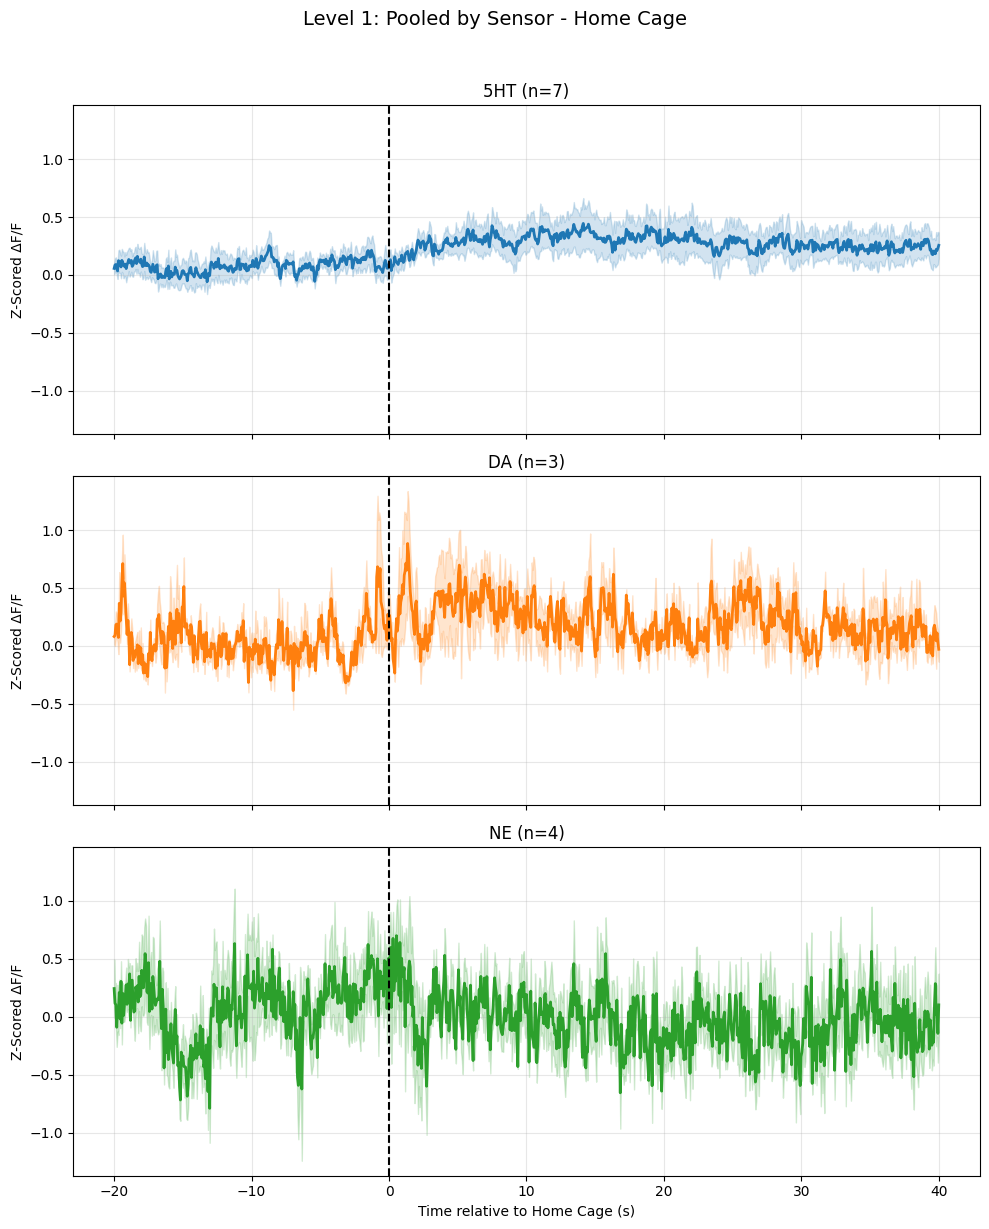

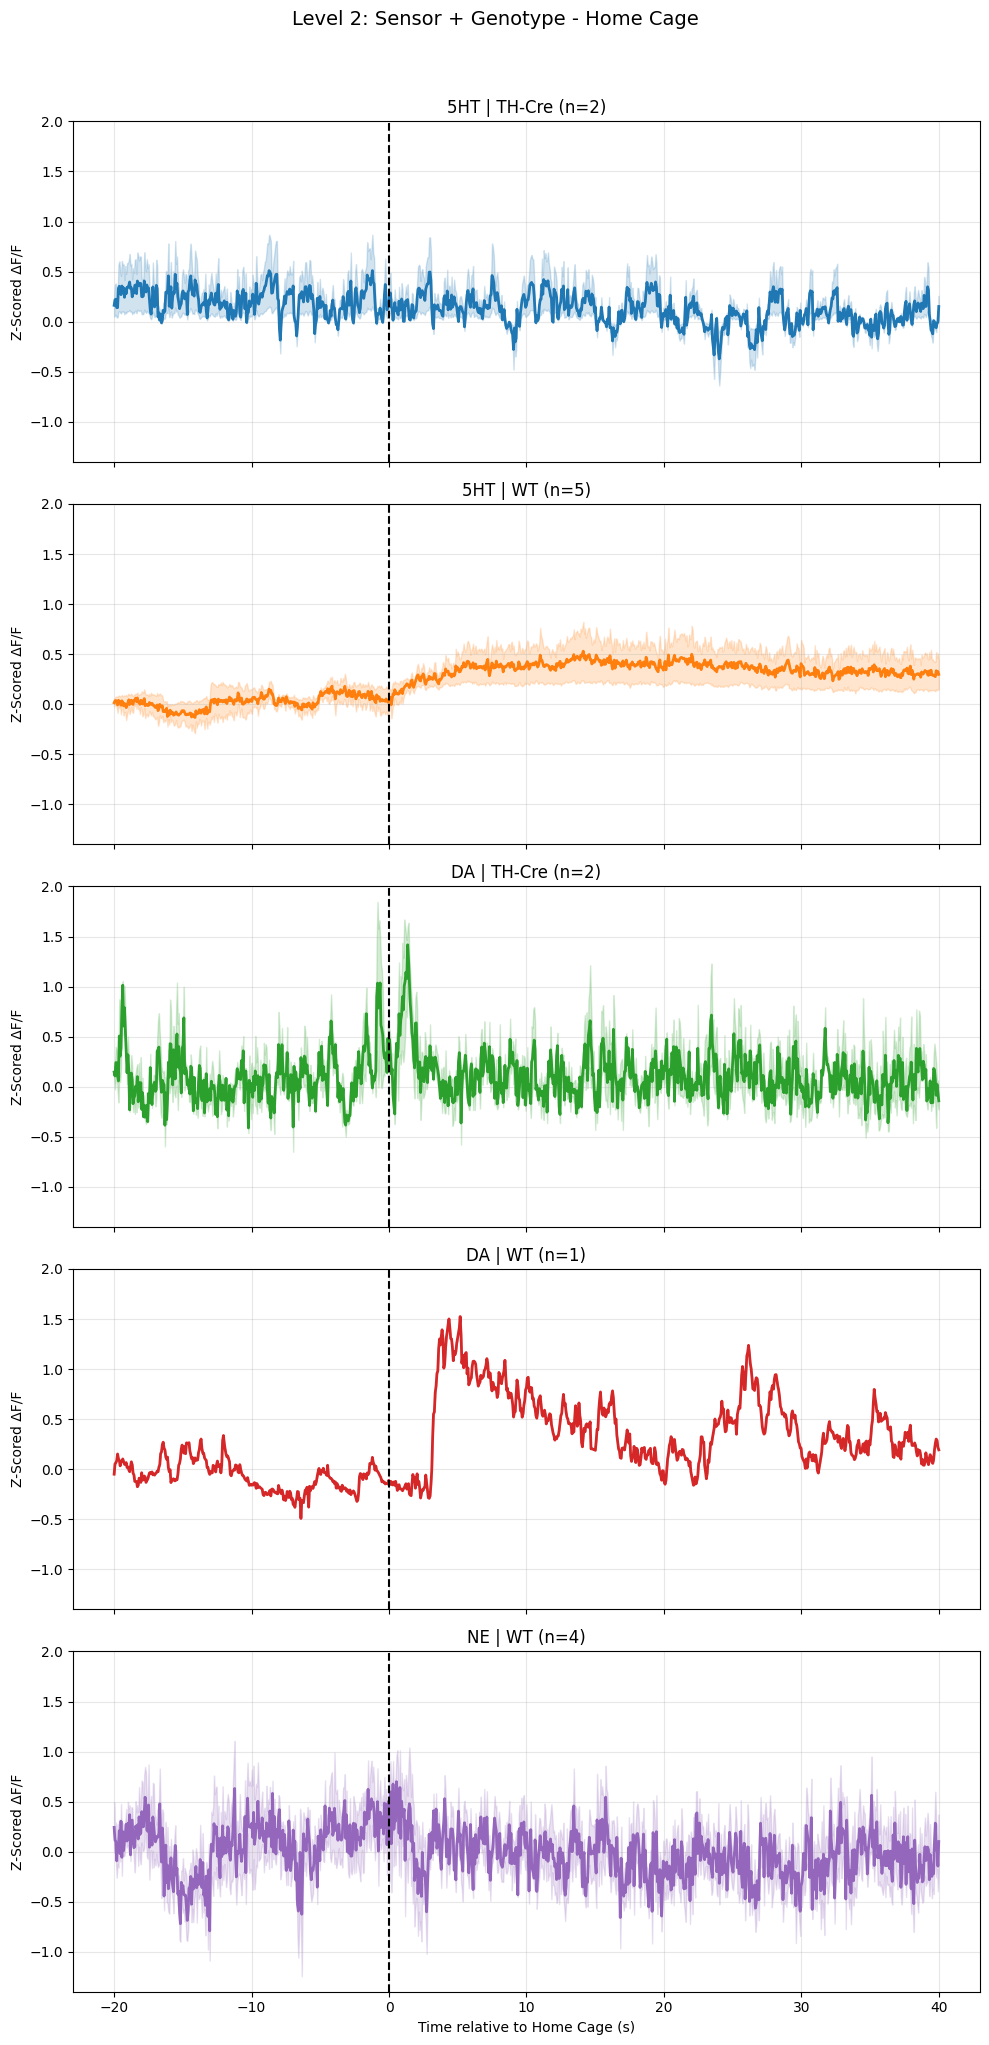

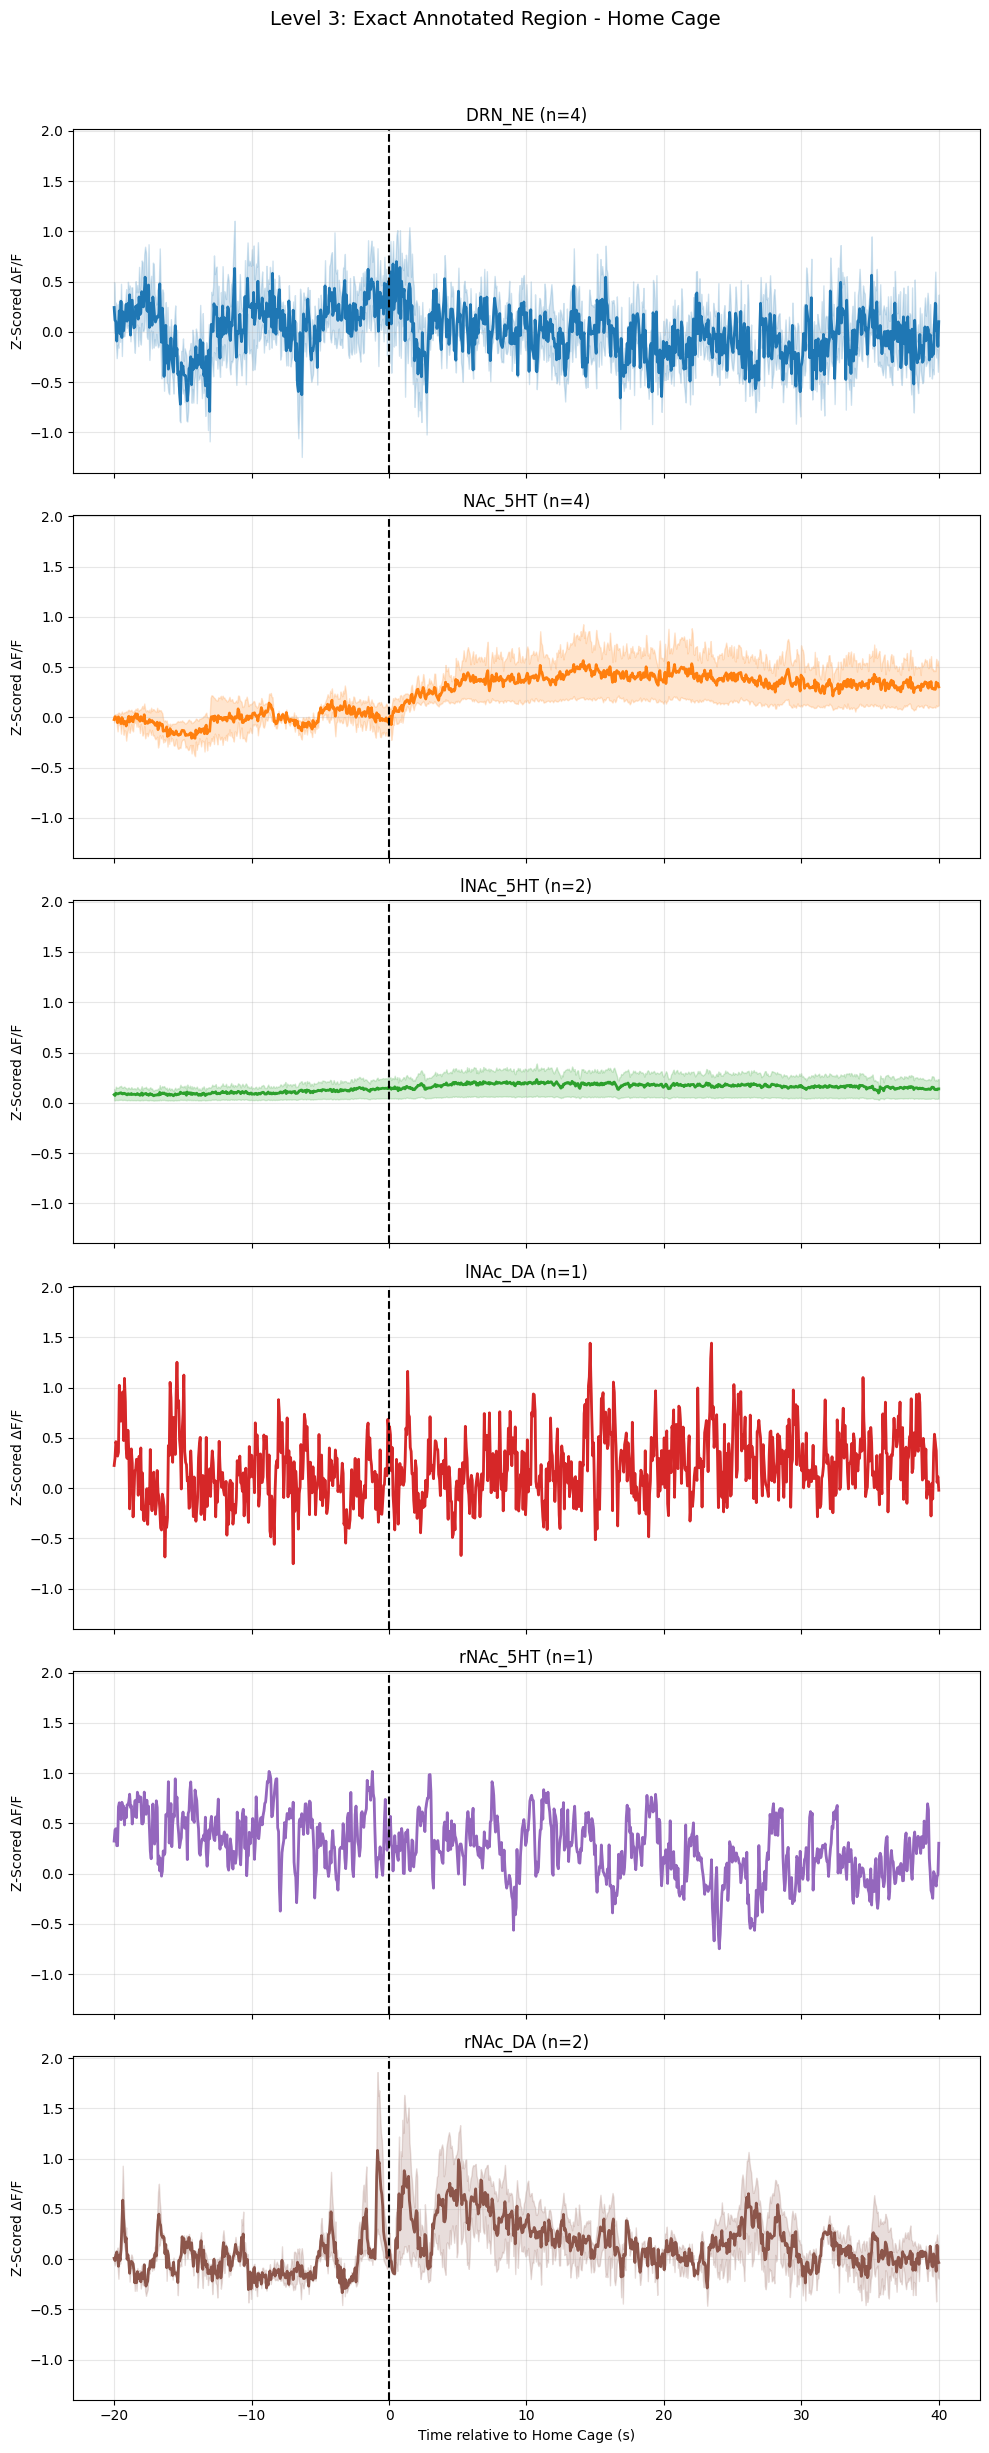


--- GENERATING PLOTS FOR EVENT: homecage_removed_min ---


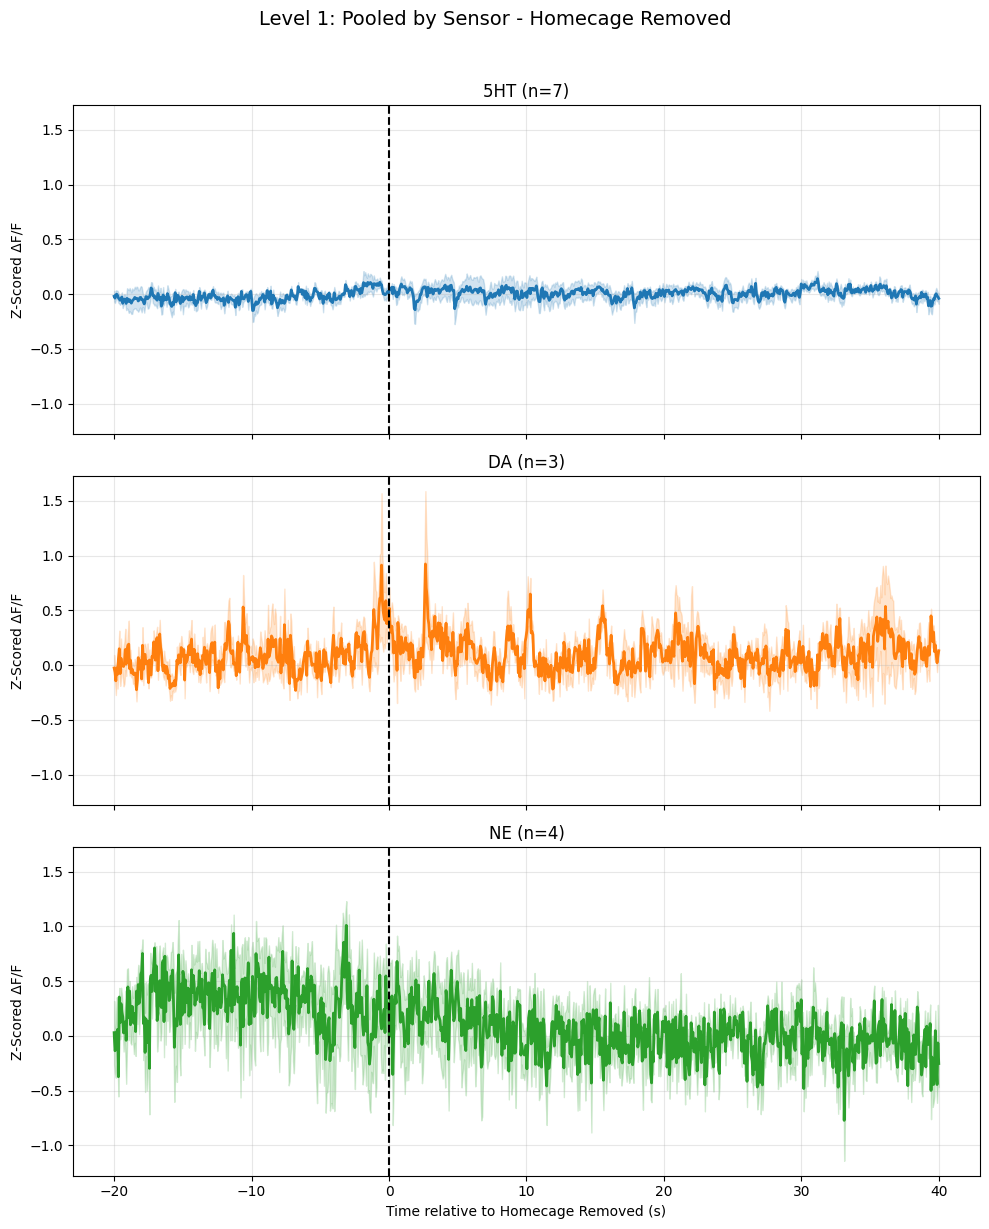

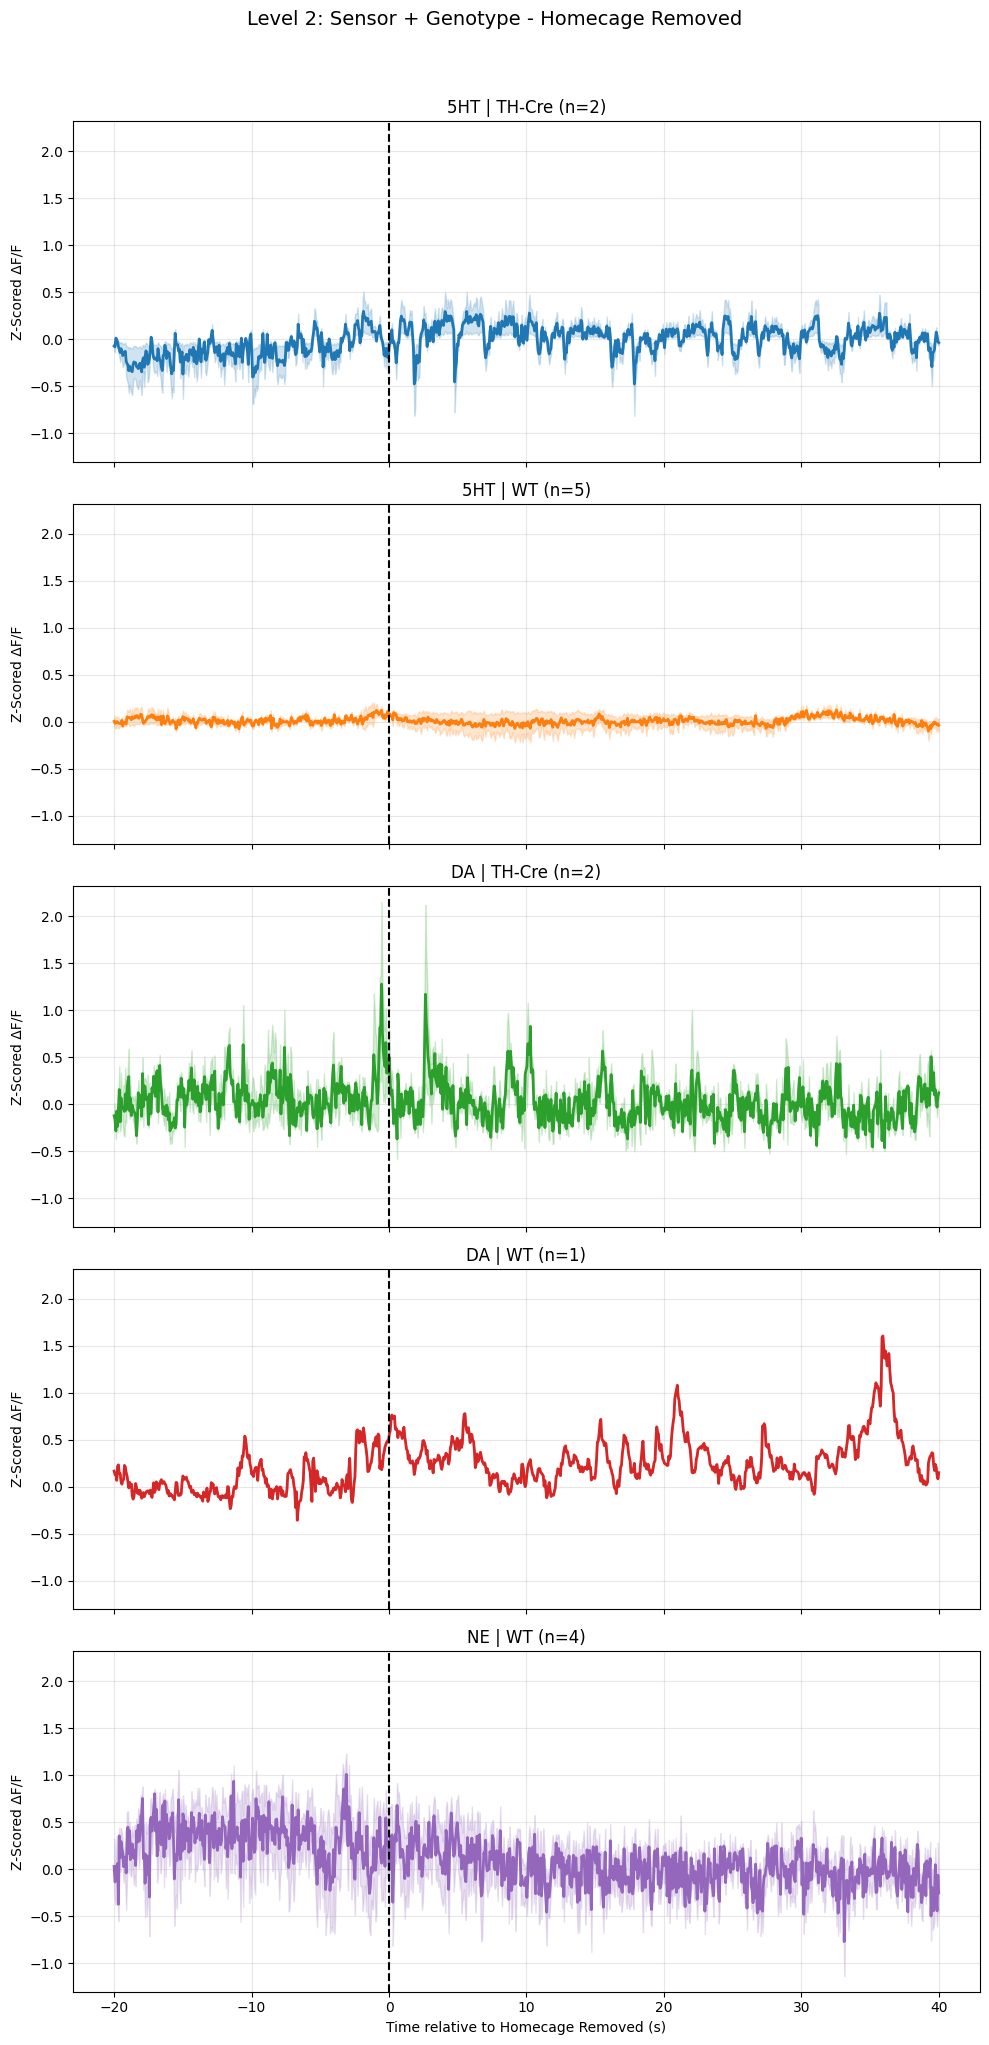

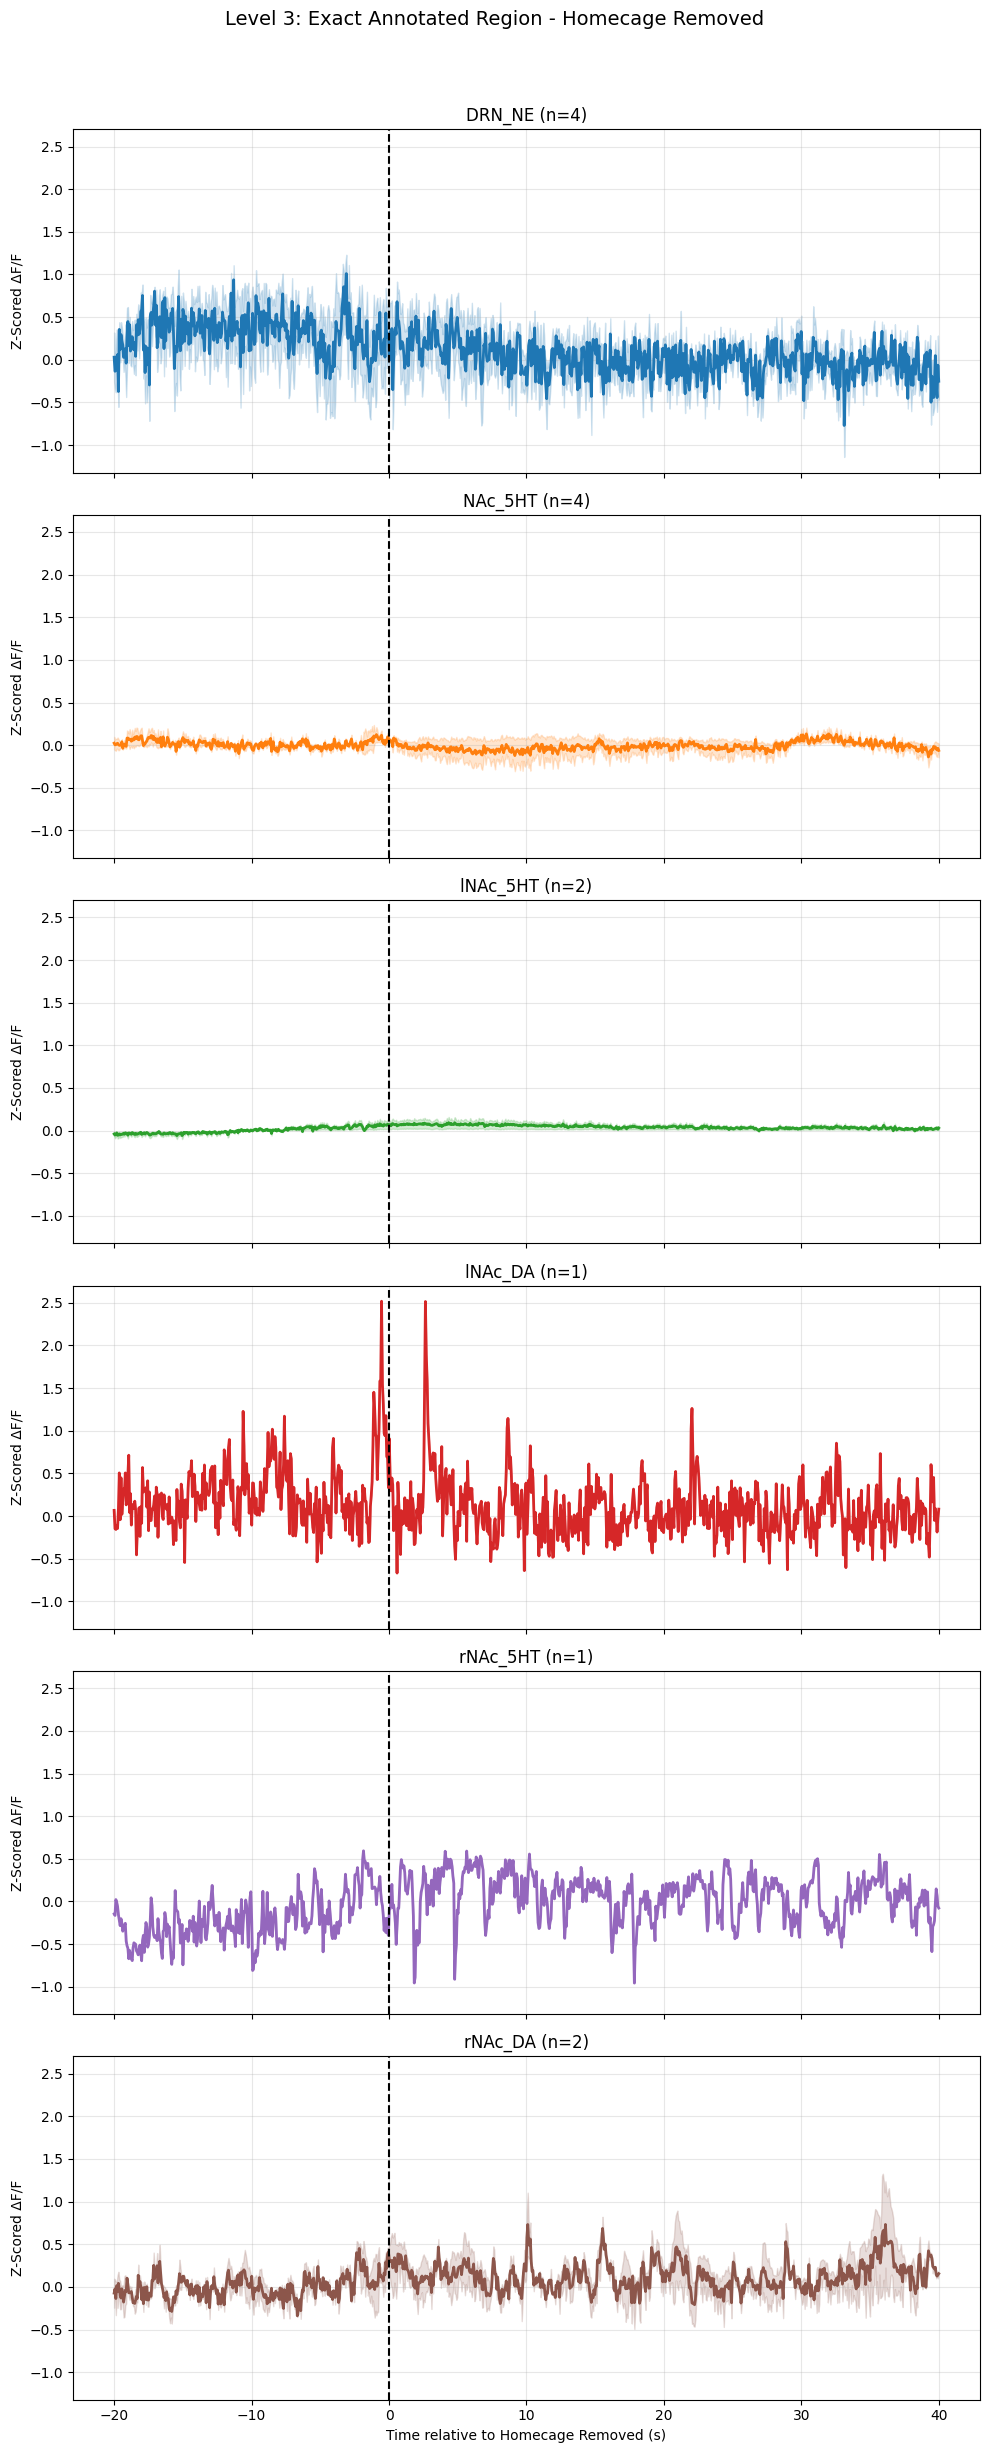


--- GENERATING PLOTS FOR EVENT: inarena_min ---


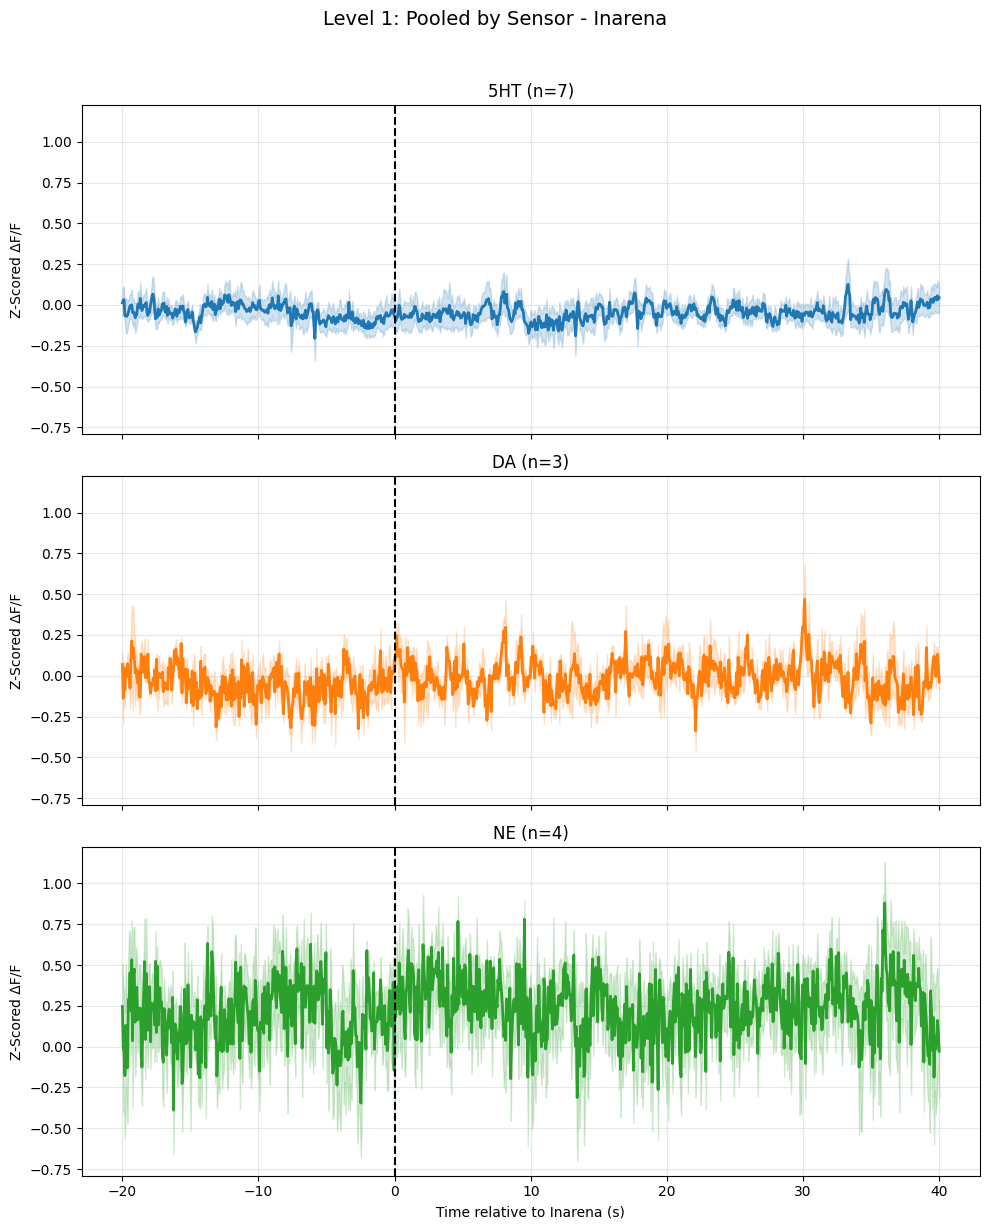

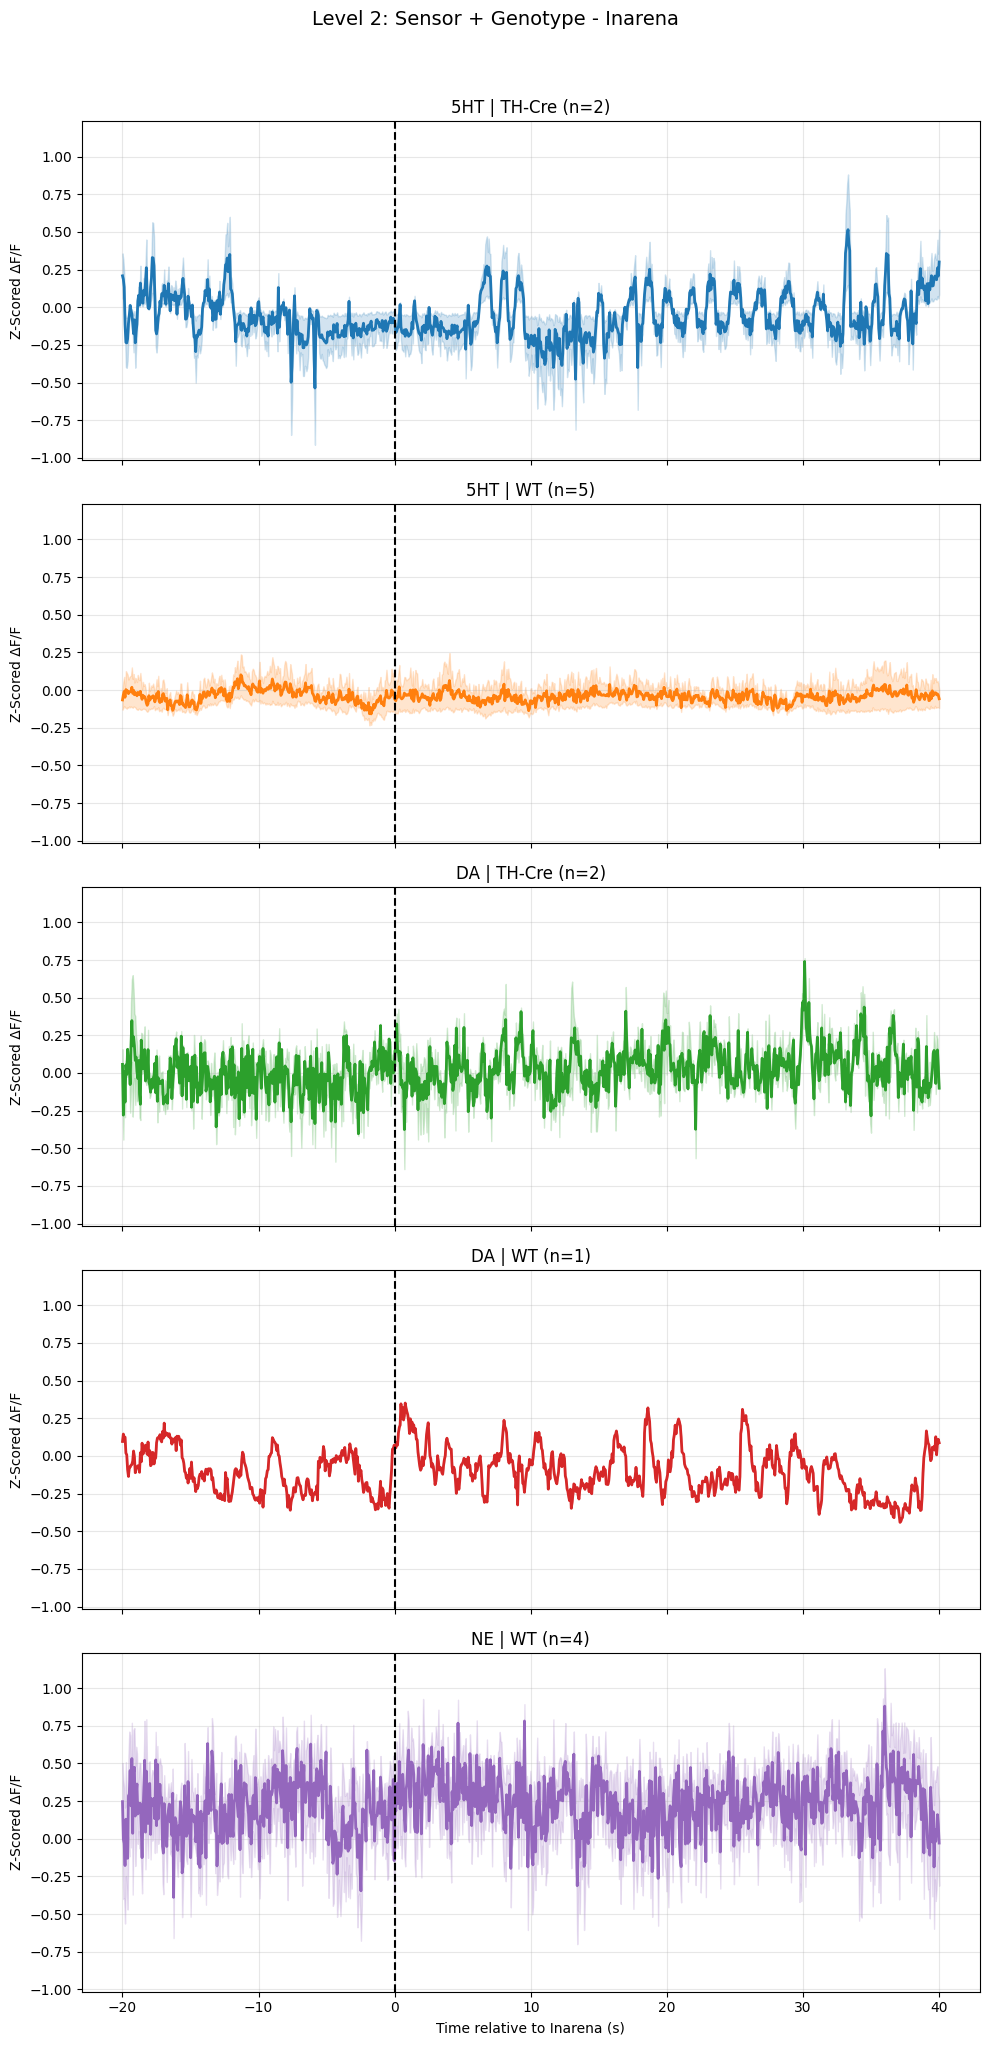

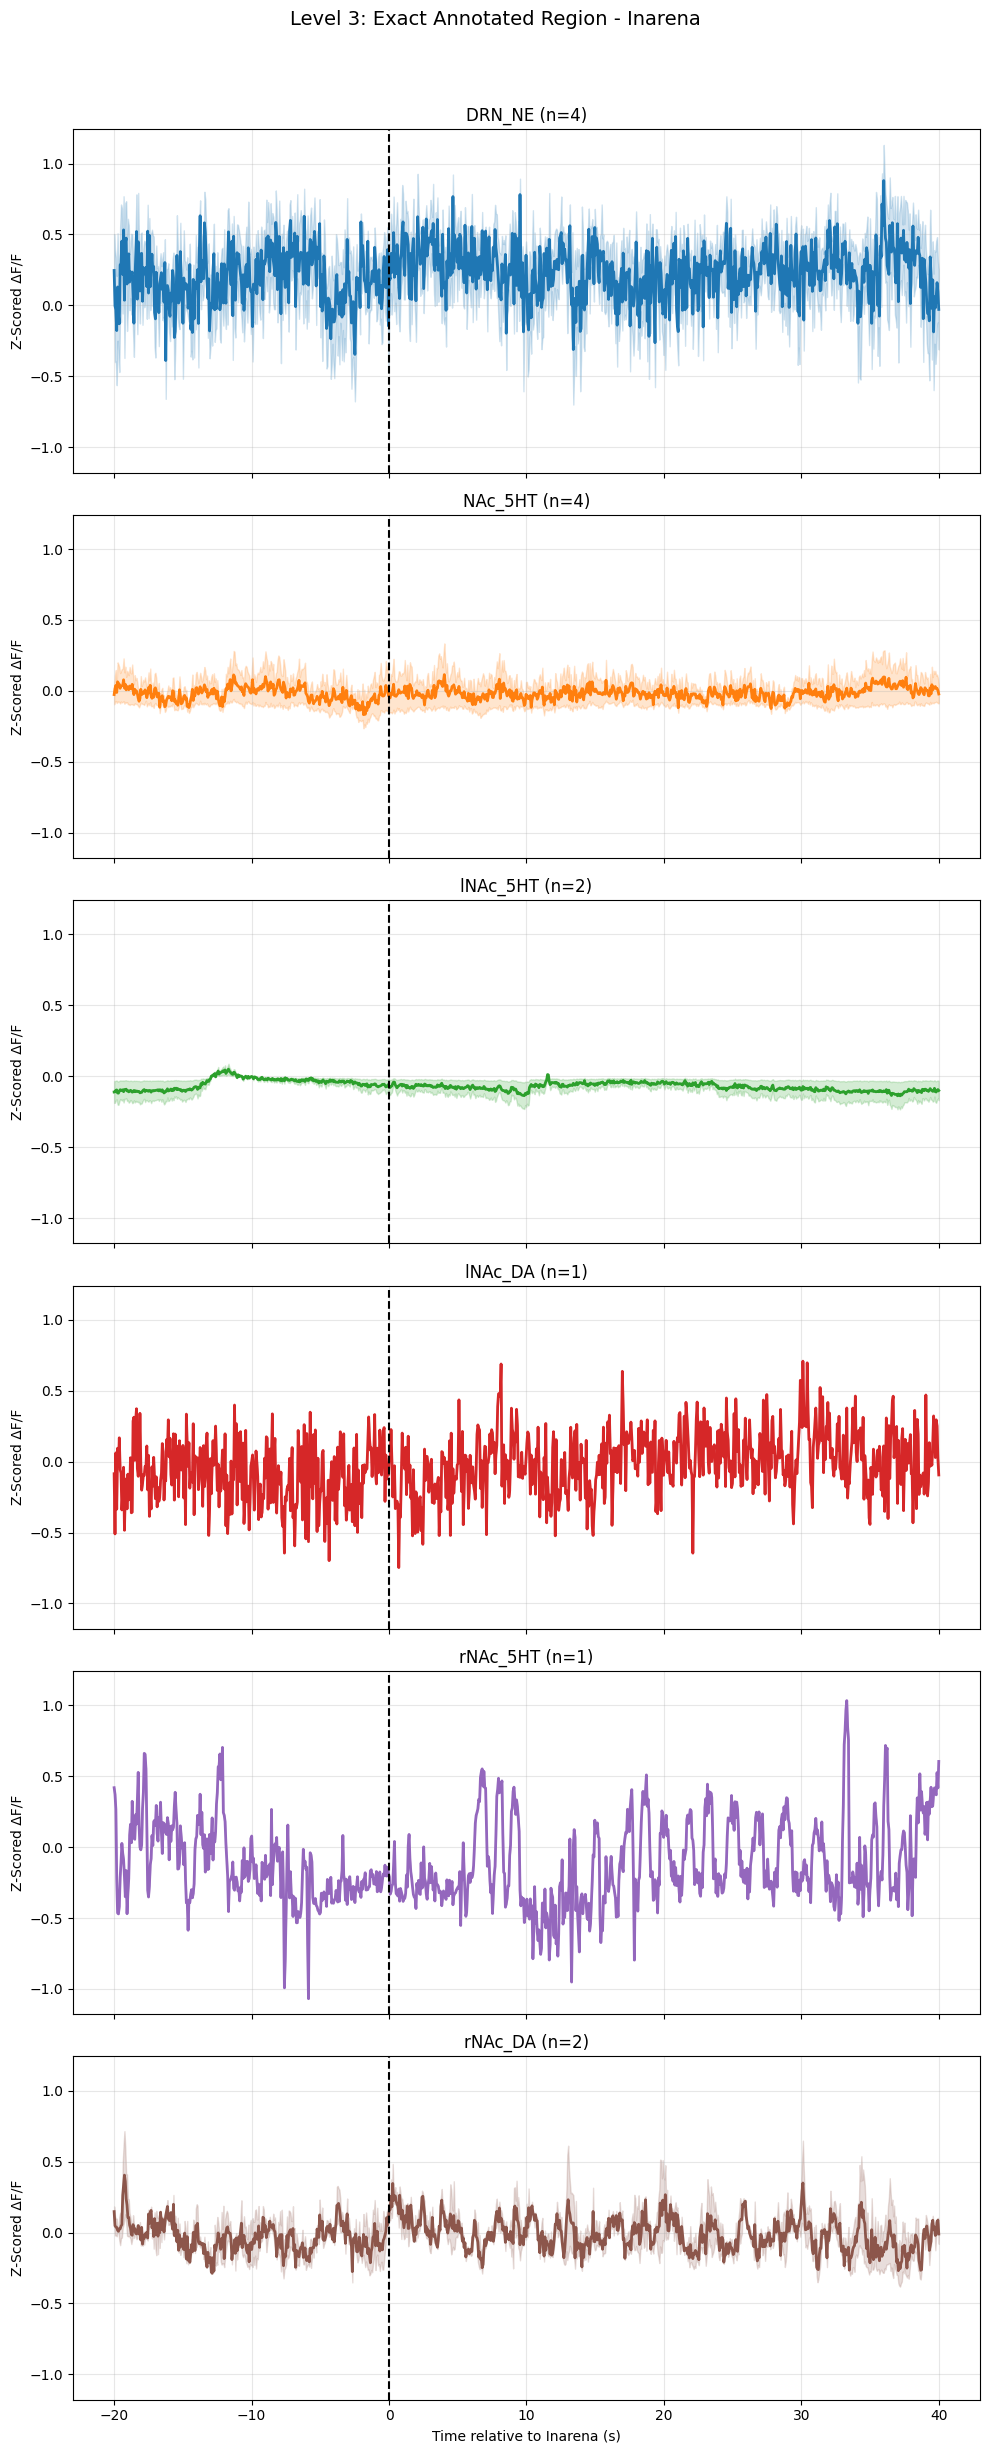


--- GENERATING PLOTS FOR EVENT: juvenile_first_sniff_min ---


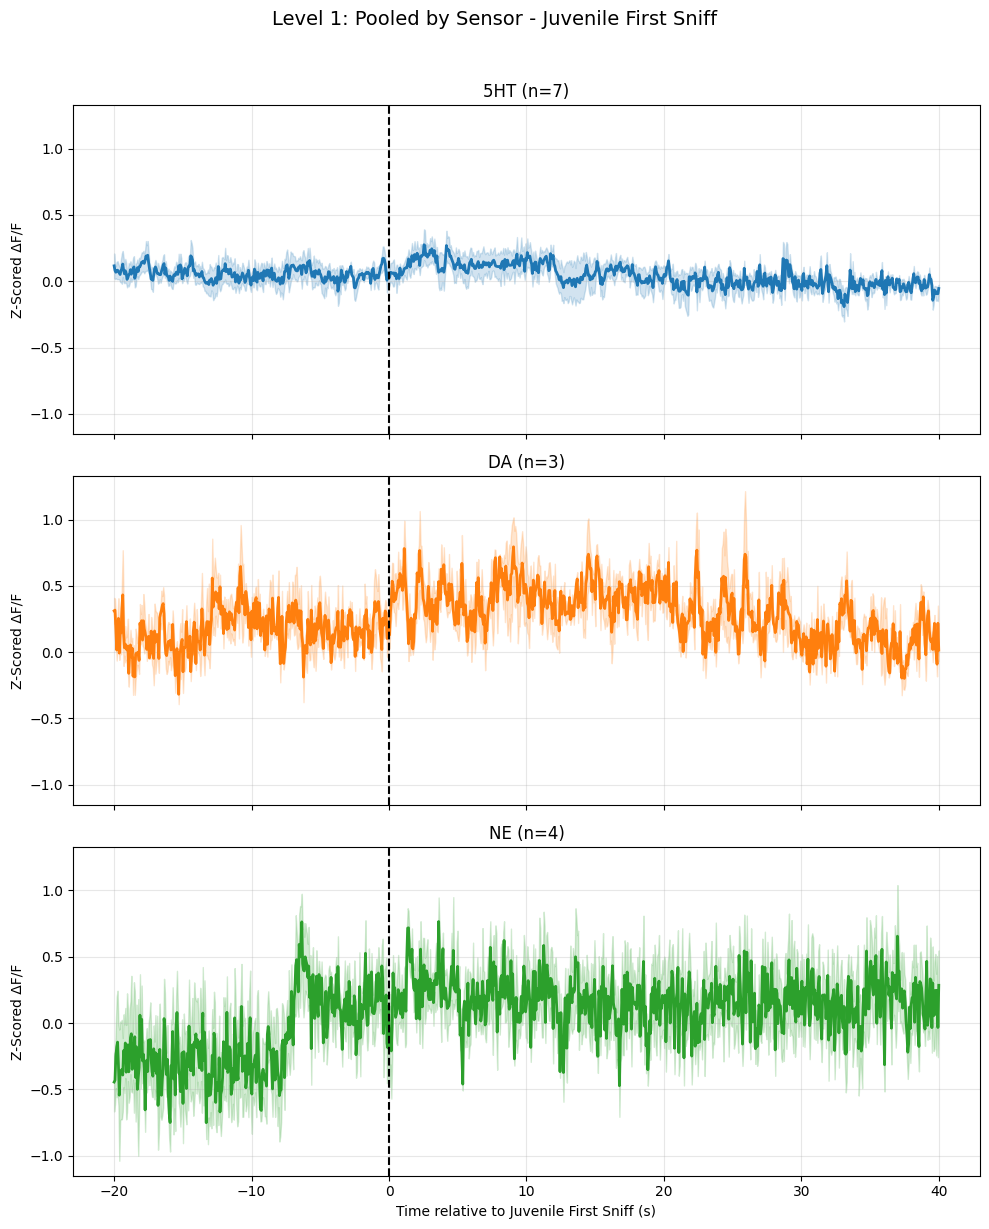

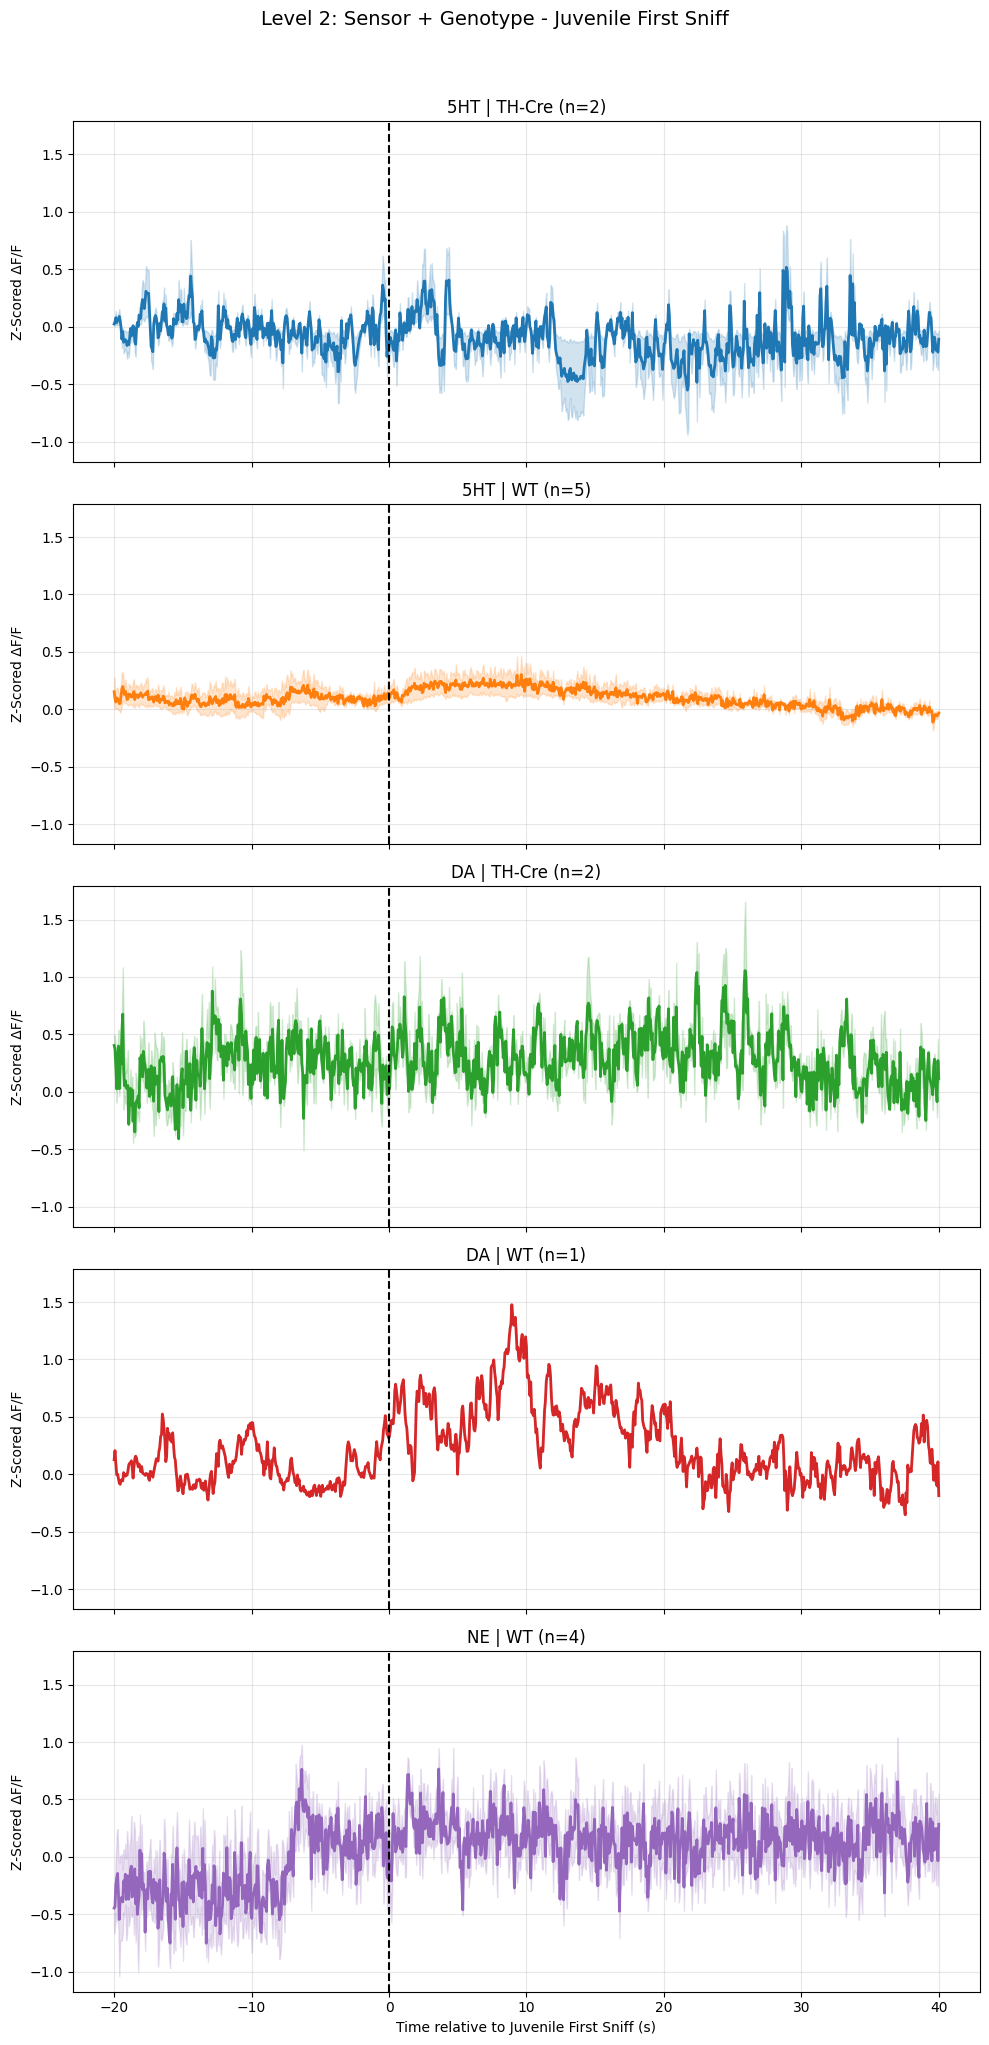

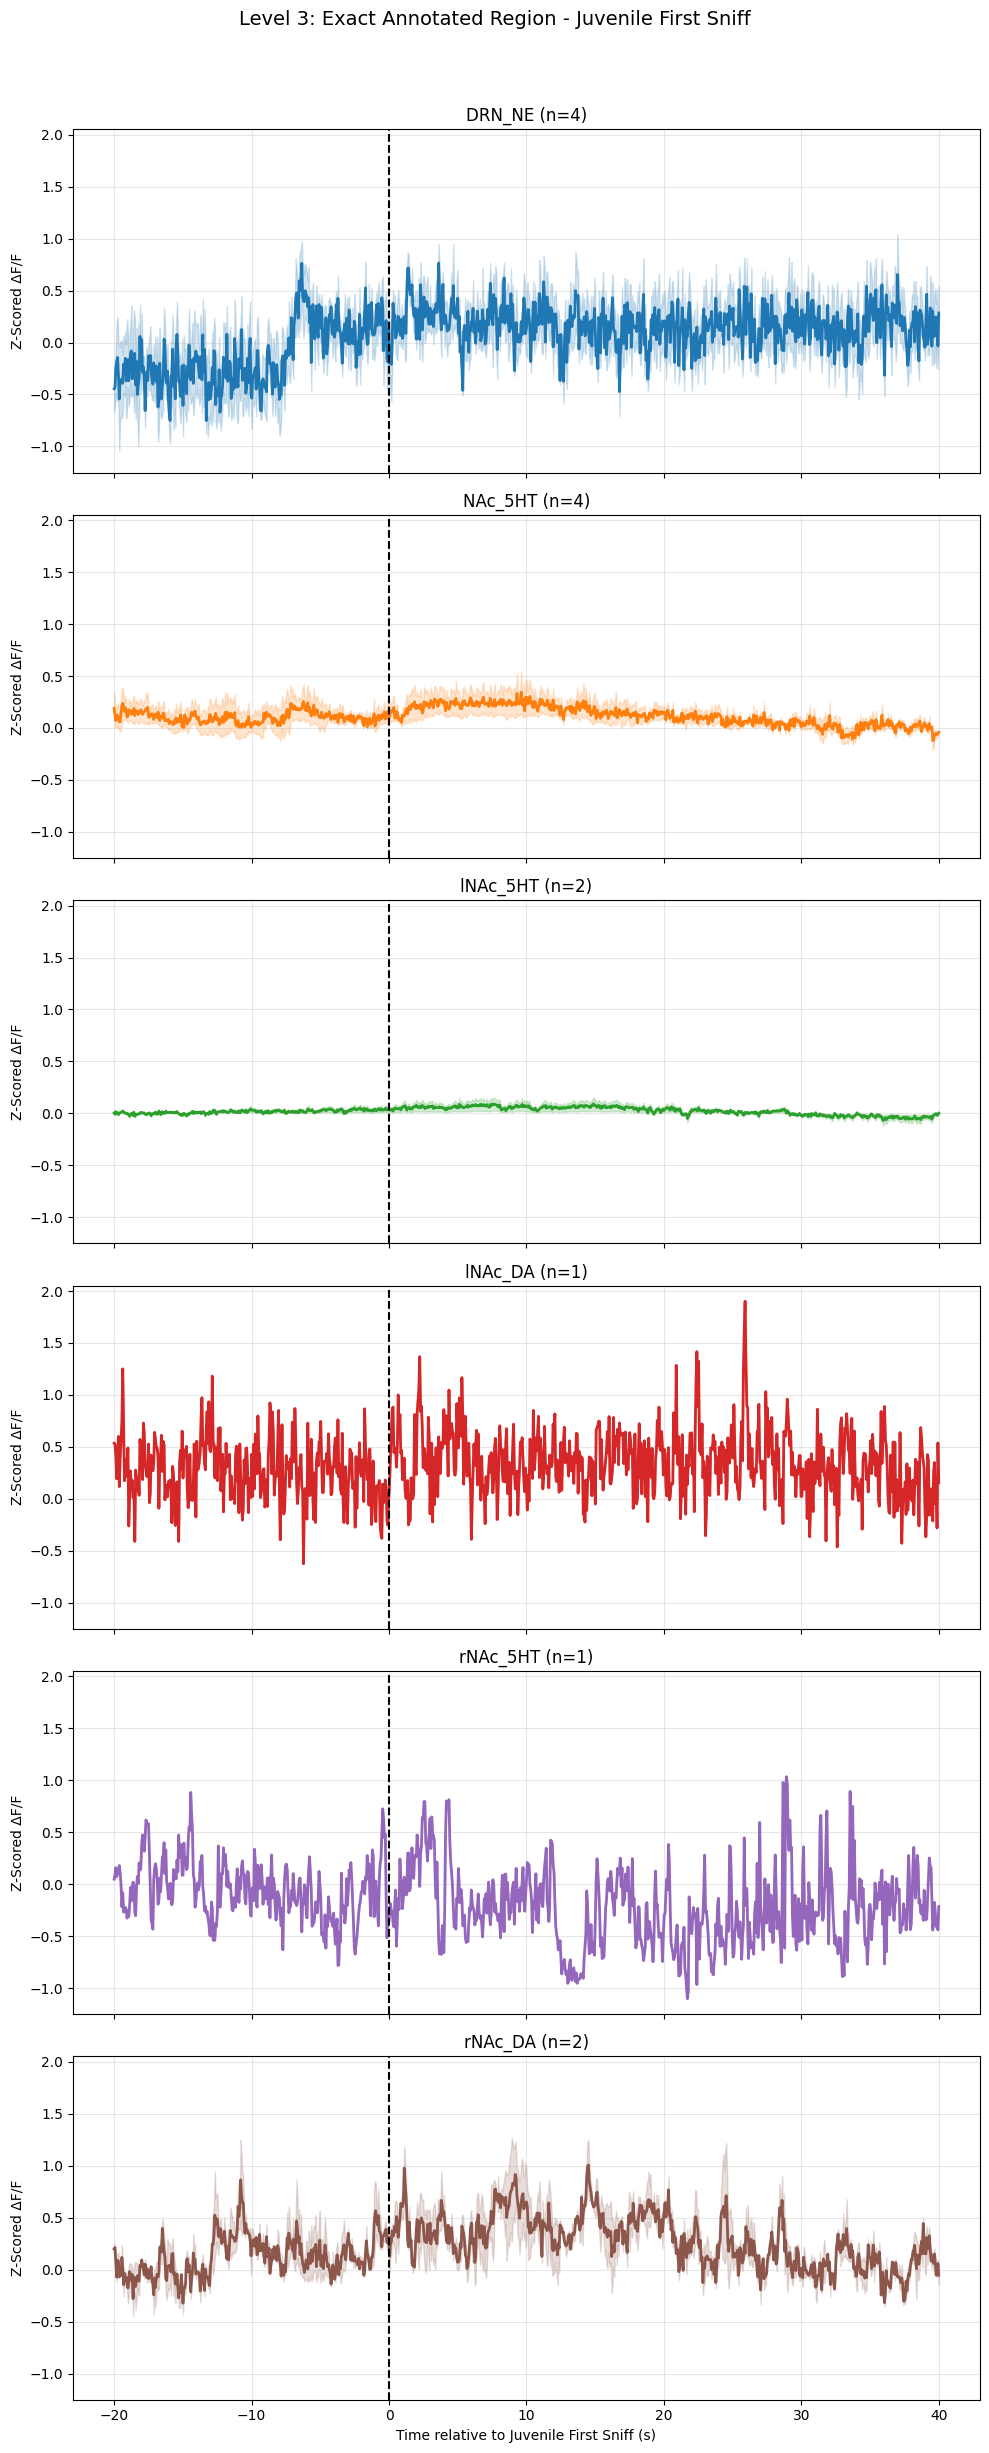


--- GENERATING PLOTS FOR EVENT: juvenile_removed_min ---


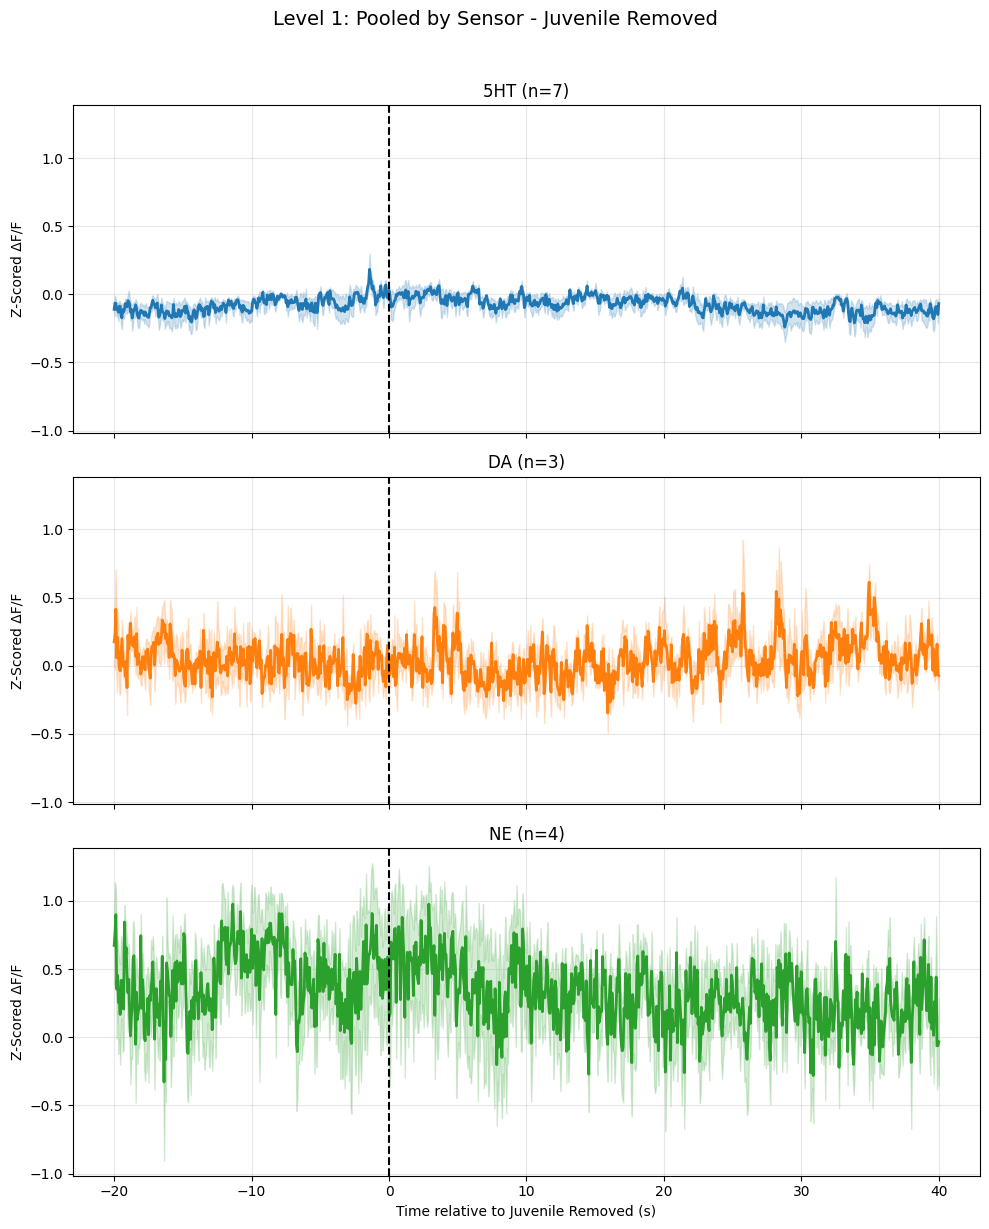

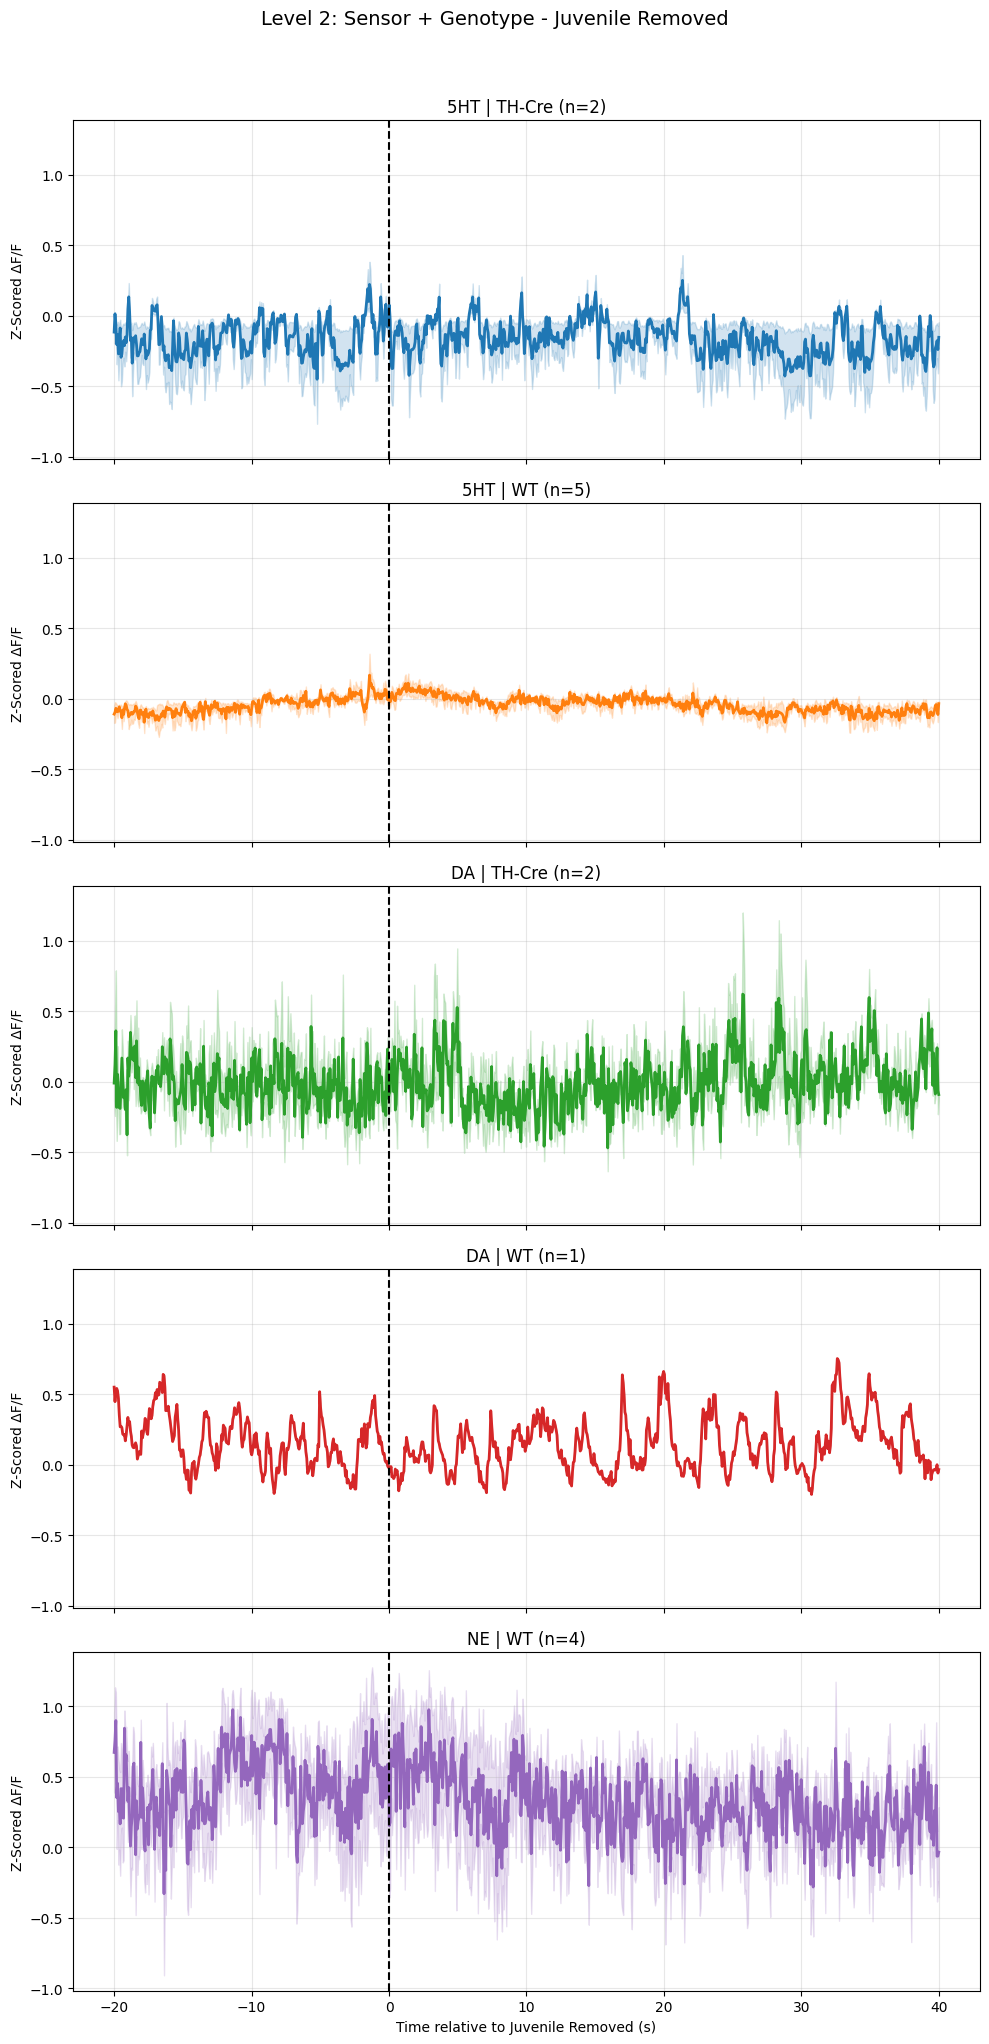

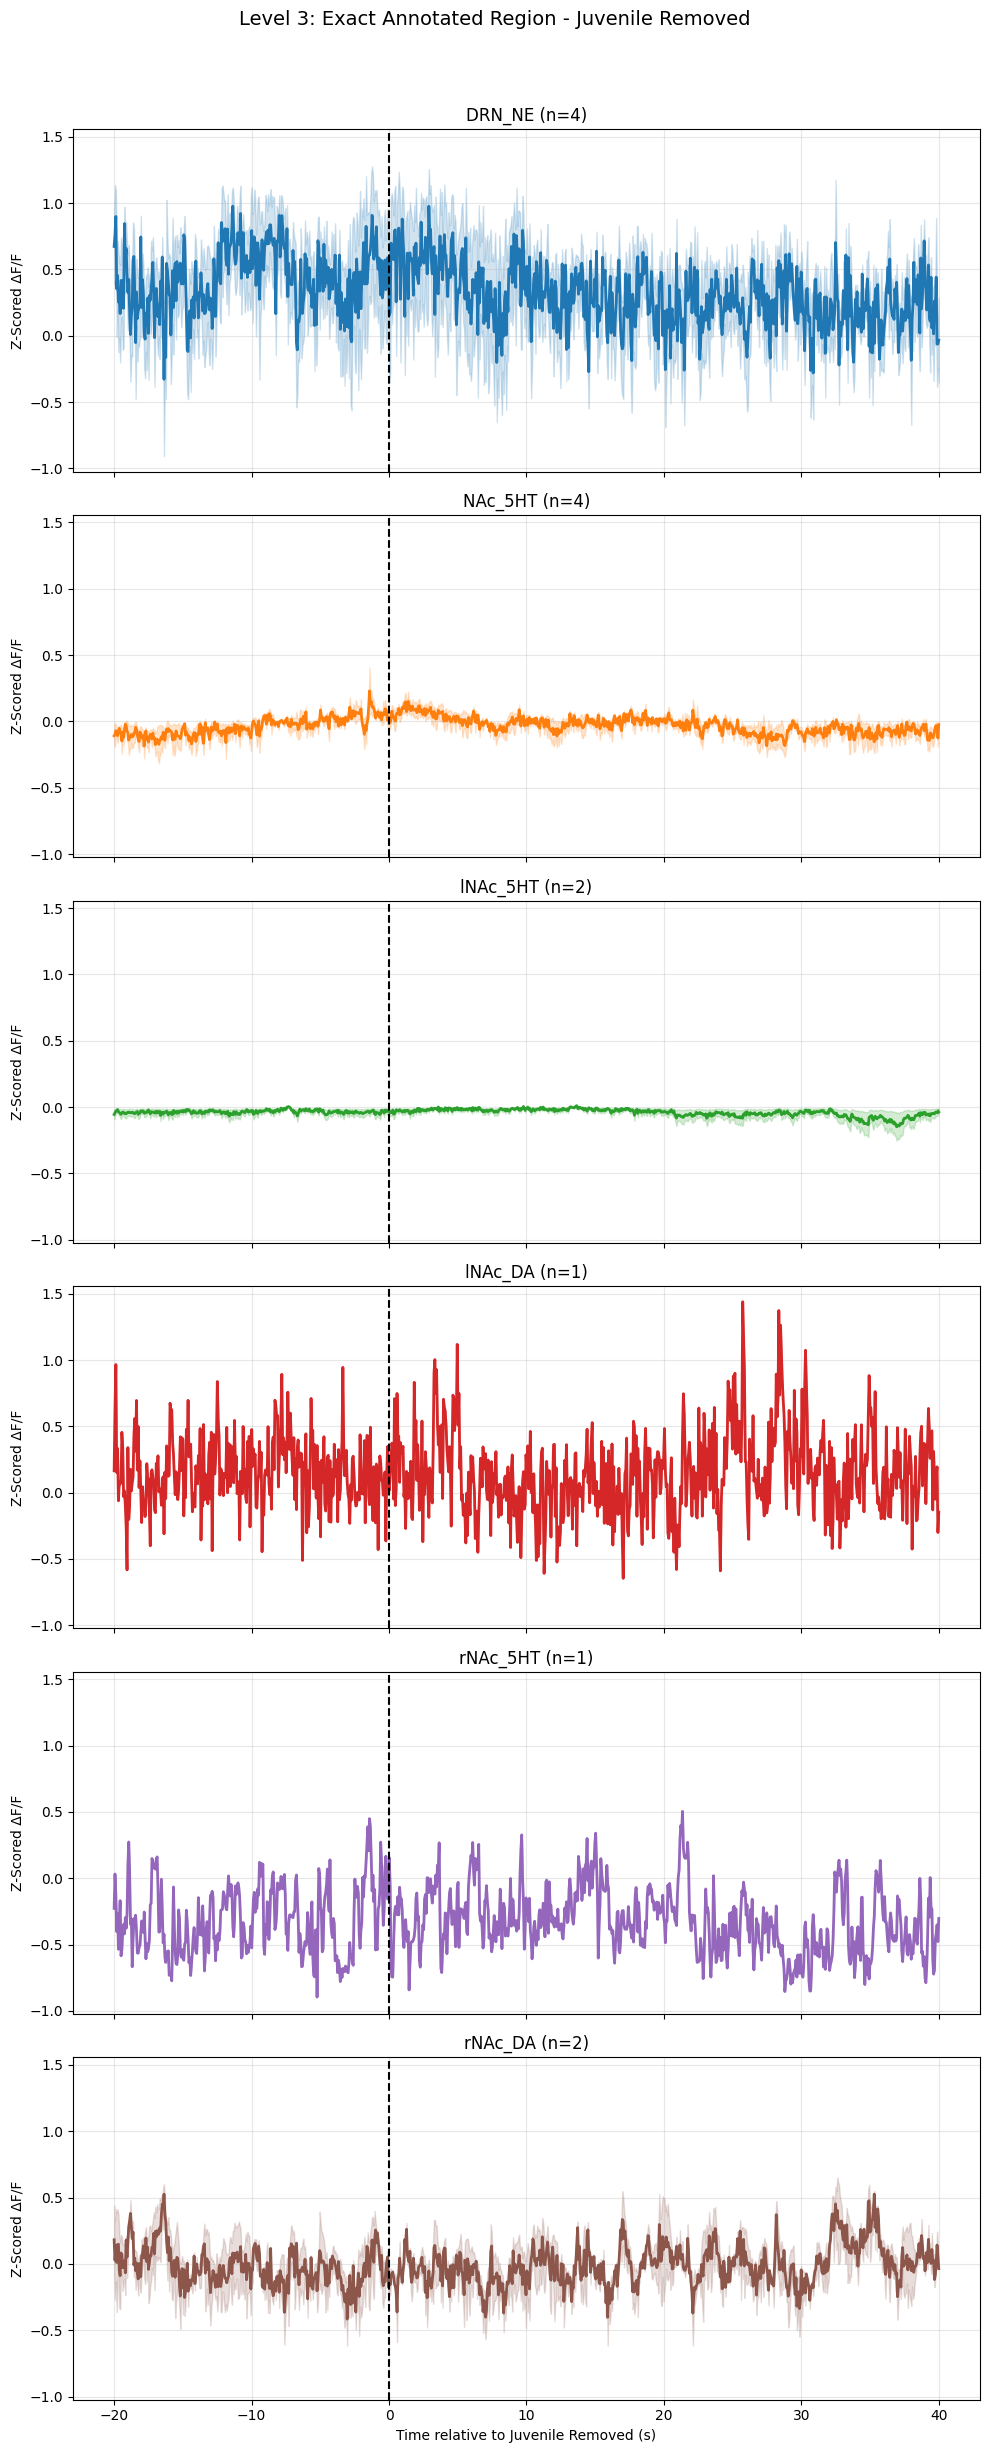

In [6]:
for event in df_signals['event'].unique():
    print(f"\n--- GENERATING PLOTS FOR EVENT: {event} ---")

    # Level 1: Pooled by Sensor
    plot_group(df_signals, ['sensor'], "Level 1: Pooled by Sensor", f"peth_{event}_lvl1.png", event)

    # Level 2: Medium (Sensor + Genotype)
    plot_group(df_signals, ['sensor', 'genotype'], "Level 2: Sensor + Genotype", f"peth_{event}_lvl2.png", event)

    # Level 3: Fine (Exact Region)
    plot_group(df_signals, ['region'], "Level 3: Exact Annotated Region", f"peth_{event}_lvl3.png", event)
